# COMP9444 Group Project: Disease Named Entity Recognition using Pre-trained Language Models

Team HAHA: Bai Li, Chongli Chen, Yuanquan Jin, Yuchen Li and Alex Shen.

## 1. Introduction

Disease Named Entity Recognition (NER) is an important task in biomedical natural language processing. It aims to identify disease mentions in biomedical text, such as scientific articles and medical documents.

In this project, we investigate the performance of three pre-trained language models on the NCBI Disease dataset:

- BERT
- BioBERT
- PubMedBERT

The objective is to compare the performance of general-domain and biomedical-domain pre-trained language models on disease entity recognition.

We evaluate the models using precision, recall, F1-score, and accuracy. We also analyse their prediction errors to better understand the strengths and limitations of each model. Finally, we test whether domain-adaptive pre-training of BERT on unlabelled PubMed abstracts narrows the gap to the biomedical models (Section 12).

## 2. Environment Setup

We use Python, PyTorch, and Hugging Face Transformers to implement and evaluate the three baseline models.

A fixed random seed is used to improve the reproducibility of our experiments.

In [1]:
# Basic imports and environment setup
import os

# Stop transformers from trying to load TensorFlow; we only use PyTorch
os.environ["USE_TF"] = "0"
os.environ["USE_TORCH"] = "1"

import sys
import random
import numpy as np
import pandas as pd
import torch

# Record the versions used so the results can be reproduced
print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)

Python version: 3.11.17 (main, Oct  1 2026, 20:09:52) [Clang 20.1.8 ]
PyTorch version: 2.15.0


In [2]:
# Fix the random seeds and pick the best available device
SEED = 42

# Seed Python, NumPy and PyTorch so runs are repeatable
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Prefer a CUDA GPU, then Apple Silicon (MPS), otherwise fall back to the CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Random seed:", SEED)
print("Device:", device)

Random seed: 42
Device: mps


## 3. Dataset

We use the NCBI Disease dataset for disease named entity recognition.

The dataset contains biomedical text annotated with disease mentions. Each sentence consists of a sequence of tokens and their corresponding NER labels.

The dataset is divided into three subsets:

- Training set: used to train the models.
- Validation set: used to evaluate model performance during training.
- Test set: used to evaluate the final performance of each model.

The dataset uses the BIO tagging scheme:

- B-Disease: the beginning of a disease entity.
- I-Disease: a token inside a disease entity.
- O: a token that does not belong to any disease entity.

In [3]:
# Load the NCBI Disease corpus (train/validation/test splits) from the Hugging Face Hub
from datasets import load_dataset

dataset = load_dataset("ncbi/ncbi_disease")

print(dataset)

/opt/anaconda3/envs/neuralnet/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 5433
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 924
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 941
    })
})


In [4]:
# Check the size of each split and look at one raw training example
print("Training samples:", len(dataset["train"]))
print("Validation samples:", len(dataset["validation"]))
print("Test samples:", len(dataset["test"]))

print("\nExample from the training set:")
print(dataset["train"][0])

Training samples: 5433
Validation samples: 924
Test samples: 941

Example from the training set:
{'id': '0', 'tokens': ['Identification', 'of', 'APC2', ',', 'a', 'homologue', 'of', 'the', 'adenomatous', 'polyposis', 'coli', 'tumour', 'suppressor', '.'], 'ner_tags': [0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 2, 2, 0, 0]}


### 3.1 Exploratory Data Analysis

We examine the distribution of BIO labels and sentence lengths in the NCBI Disease dataset.

The label distribution helps us understand the class imbalance between disease and non-disease tokens. Sentence length analysis provides information about the input sequences and helps identify potential tokenization and truncation challenges.

In [37]:
# Count how many tokens carry each BIO label in every split
from collections import Counter

# Map the integer tag ids back to label names (O, B-Disease, I-Disease)
dataset_label_names = dataset["train"].features["ner_tags"].feature.names

label_counts = {}

# Tally the label of every token, split by split
for split in ["train", "validation", "test"]:

    counts = Counter()

    for sample in dataset[split]:
        for tag in sample["ner_tags"]:
            counts[dataset_label_names[tag]] += 1

    label_counts[split] = counts

# Put the counts into a table with one column per split
label_distribution_df = pd.DataFrame(label_counts)

display(label_distribution_df)

,train,validation,test
O,124819,22092,22450
B-Disease,5145,787,960
I-Disease,6122,1090,1087


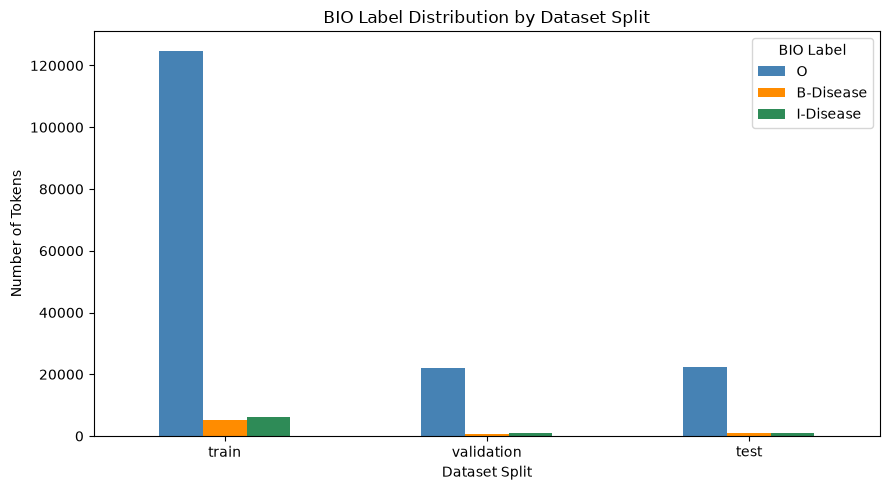

In [38]:
# Bar chart of the BIO label counts for each split
import matplotlib.pyplot as plt

# Transpose so each split becomes a group of bars, one bar per label
label_distribution_df.T.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "darkorange", "seagreen"]
)

# Titles, axis labels and legend
plt.title("BIO Label Distribution by Dataset Split")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Tokens")
plt.xticks(rotation=0)
plt.legend(title="BIO Label")

plt.tight_layout()
plt.show()

,train,validation,test
Mean,25.05,25.97,26.06
Median,23.00,24.00,24.00
Maximum,123.00,86.00,106.00


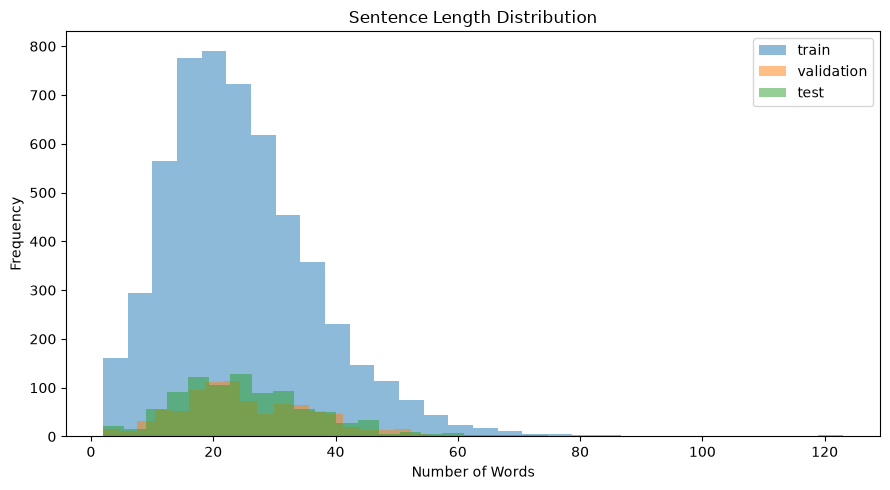

In [39]:
# Look at sentence lengths (in words) across the three splits
sentence_lengths = {}

# Collect the length of each sentence, skipping empty samples
for split in ["train", "validation", "test"]:

    sentence_lengths[split] = [
        len(sample["tokens"])
        for sample in dataset[split]
        if len(sample["tokens"]) > 0
    ]

# Summary statistics of sentence length per split
length_summary = pd.DataFrame({
    split: {
        "Mean": np.mean(lengths),
        "Median": np.median(lengths),
        "Maximum": np.max(lengths)
    }
    for split, lengths in sentence_lengths.items()
})

display(length_summary.round(2))

# Overlaid histograms to compare the length distributions
plt.figure(figsize=(9, 5))

for split, lengths in sentence_lengths.items():
    plt.hist(
        lengths,
        bins=30,
        alpha=0.5,
        label=split
    )

plt.title("Sentence Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.show()

### 3.2 Exploratory Analysis Findings

The BIO label distribution shows a clear class imbalance across all three dataset splits.

In the training set, approximately 91.7% of tokens are labelled O, while disease-related tokens account for only 8.3%. This imbalance explains why token-level accuracy alone may not provide a reliable measure of disease recognition performance. Therefore, we use entity-level F1-score as the primary evaluation metric.

The sentence length analysis shows similar distributions across the three dataset splits. The average sentence length ranges from approximately 25 to 26 words, with median lengths of 23 to 24 words.

The longest sentence contains 123 words in the training set. Although the original sentences are relatively short, subword tokenization may increase their lengths. We therefore consider the maximum input length when preparing data for the pre-trained models.

### 3.3 Disease Mention Lengths

A mention begins at B-Disease and includes the following I-Disease words until an O, another B-Disease, or the end of the sentence. Adjacent mentions are counted separately, and lengths are measured in original words before subword tokenization.

The code uses the Hugging Face dataset loaded in Section 3. Once empty records are skipped, its sentences and labels match the CoNLL files exactly (see Section 4), so the counts are the same as in the data-exploration notebook (`parts/1_intro_data_eda.ipynb`).

,1 word,2 words,3 words,4+ words,Total
train,2266,1402,643,834,5145
validation,283,225,122,157,787
test,423,270,133,134,960


,Multiword mentions (%)
train,56.0
validation,64.0
test,55.9


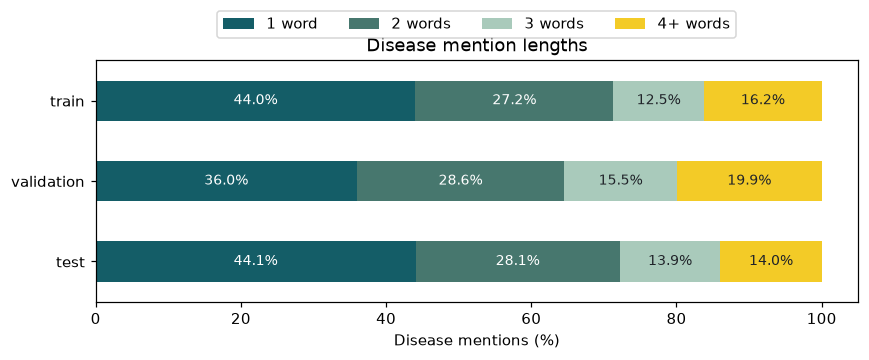

In [6]:
# Count disease mentions by length in original words, using the Hugging Face dataset loaded in Section 3
def disease_mention_lengths(tags):
    lengths = []
    current_length = 0
    # Append a final "O" so a mention at the end of the sentence is still closed off
    for tag in [*tags, "O"]:
        if tag == "I-Disease":
            assert current_length > 0, "Orphan I-Disease tag"
            current_length += 1
        # Any other tag ends the current mention, and B-Disease also starts a new one
        else:
            if current_length:
                lengths.append(current_length)
            current_length = 1 if tag == "B-Disease" else 0
    return lengths

# Turn each non-empty sentence into (tokens, BIO label names); empty records contain no mentions
data_splits = {
    split: [(sample["tokens"], [dataset_label_names[t] for t in sample["ner_tags"]])
            for sample in dataset[split] if len(sample["tokens"]) > 0]
    for split in ["train", "validation", "test"]
}

# Mention lengths for every split
mention_lengths = {
    split: [length for _, tags in rows for length in disease_mention_lengths(tags)]
    for split, rows in data_splits.items()
}
# Bucket the mentions into 1, 2, 3 and 4+ words
mention_table = pd.DataFrame.from_dict({
    split: {"1 word": sum(n == 1 for n in lengths),
            "2 words": sum(n == 2 for n in lengths),
            "3 words": sum(n == 3 for n in lengths),
            "4+ words": sum(n >= 4 for n in lengths)}
    for split, lengths in mention_lengths.items()
}, orient="index")
# Sanity check: every mention starts with exactly one B-Disease tag (counted in Section 3.1)
assert all(mention_table.loc[split].sum() == label_counts[split]["B-Disease"] for split in mention_table.index)
display(mention_table.assign(Total=mention_table.sum(axis=1)))
# Share of multiword mentions (anything longer than one word)
mention_percent = mention_table.div(mention_table.sum(axis=1), axis=0) * 100
display((100 - mention_percent["1 word"]).round(1).to_frame("Multiword mentions (%)"))
# Stacked horizontal bars showing the percentage in each length bucket
ax = mention_percent.plot.barh(
    stacked=True, color=["#145D67", "#47776E", "#A9CABB", "#F3CB27"],
    figsize=(8, 3.4))
ax.set(xlabel="Disease mentions (%)", ylabel="", title="Disease mention lengths")
ax.invert_yaxis()
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.06))
# Write the percentage inside each segment, with dark text on the lighter colours
for i, container in enumerate(ax.containers):
    ax.bar_label(container, fmt="%.1f%%", label_type="center",
                 color="white" if i < 2 else "#202329", fontsize=9)
plt.tight_layout()
plt.show()

Multiword mentions make up 56.0% of training mentions, 64.0% of validation mentions and 55.9% of test mentions, so for most mentions the model has to find the complete boundary, not just one word. These counts are given in Table II of the report.

## 4. Data Audit

Before training the models, we conduct a data audit to verify the consistency of the NCBI Disease dataset.

We compare the Hugging Face dataset with the CoNLL TSV files for the training, validation, and test splits.

The audit checks sentence counts, token sequences, BIO labels, missing rows, and invalid BIO transitions. This helps ensure that the models are evaluated using consistent and reliable data.

### 4.1 Comparison with the CoNLL Files

The audit below loads both versions of each split and compares them sentence by sentence.

In [5]:
# Data audit: check the Hugging Face copy of NCBI Disease against the original CoNLL files
"""Compare an already loaded Hugging Face NCBI Disease dataset with CoNLL TSVs."""

from collections import Counter
from hashlib import sha256
from itertools import zip_longest
from pathlib import Path
from urllib.request import urlopen


# Raw CoNLL files from the spyysalo/ncbi-disease repository and the matching split names
CONLL_URL = "https://raw.githubusercontent.com/spyysalo/ncbi-disease/master/conll/"
SPLIT_FILES = {"train": "train.tsv", "validation": "devel.tsv", "test": "test.tsv"}
LABEL_NAMES = ("O", "B-Disease", "I-Disease")


# Parse a CoNLL TSV file into a list of (tokens, tags) sentences
def read_conll(raw):
    rows = []
    tokens, tags = [], []
    # Blank lines separate sentences; every other line is token<TAB>tag
    for line_number, line in enumerate(raw.decode("utf-8").splitlines(), start=1):
        if not line.strip():
            if tokens:
                rows.append((tokens, tags))
                tokens, tags = [], []
            continue

        # Reject malformed rows or unknown tags instead of silently skipping them
        token, separator, tag = line.partition("\t")
        tag = tag.rstrip()
        if not separator or not token or tag not in LABEL_NAMES:
            raise ValueError(f"Invalid CoNLL row on line {line_number}: {line!r}")
        tokens.append(token)
        tags.append(tag)

    # Keep the last sentence if the file does not end with a blank line
    if tokens:
        rows.append((tokens, tags))
    return rows


def audit_ncbi_splits(hf_dataset, conll_dir=None):
    """Print split statistics and return True when all ordered rows match."""
    all_match = True
    for split, filename in SPLIT_FILES.items():
        # Download the CoNLL file, or read it from a local folder when conll_dir is given
        if conll_dir is None:
            with urlopen(CONLL_URL + filename, timeout=60) as response:
                raw = response.read()
        else:
            raw = (Path(conll_dir) / filename).read_bytes()

        # Parse the CoNLL file and get the matching Hugging Face split and label names
        conll_rows = read_conll(raw)
        hf_rows = hf_dataset[split]
        hf_labels = hf_rows.features["ner_tags"].feature
        # Counters for each kind of disagreement between the two sources
        token_mismatches = label_mismatches = missing_rows = invalid_bio = 0
        tag_counts = Counter()
        first_difference = None

        # Compare row by row; zip_longest also catches splits with different lengths
        for row_number, (hf_row, conll_row) in enumerate(zip_longest(hf_rows, conll_rows)):
            hf_value = None
            if hf_row is not None:
                tokens = hf_row["tokens"]
                tags = [hf_labels.int2str(tag) for tag in hf_row["ner_tags"]]
                if len(tokens) != len(tags) or not set(tags).issubset(LABEL_NAMES):
                    raise ValueError(f"Invalid Hugging Face row: {split}[{row_number}]")
                hf_value = (tokens, tags)
                tag_counts.update(tags)
                # An I-Disease tag directly after O is an invalid BIO sequence
                previous = "O"
                for tag in tags:
                    invalid_bio += tag == "I-Disease" and previous == "O"
                    previous = tag

            # Count missing rows and token/label mismatches, keeping the first difference for printing
            if hf_value is None or conll_row is None:
                missing_rows += 1
            else:
                token_mismatches += hf_value[0] != conll_row[0]
                label_mismatches += hf_value[1] != conll_row[1]
            if hf_value != conll_row and first_difference is None:
                first_difference = (row_number, hf_value, conll_row)

        # Print a summary for this split, including a hash of the CoNLL file
        matches = first_difference is None
        all_match &= matches
        print(f"\n{split}: {'EXACT MATCH' if matches else 'DIFFERENT'}")
        print(f"  Sentences: Hugging Face={len(hf_rows)}, CoNLL={len(conll_rows)}")
        print(f"  Rows with different tokens: {token_mismatches}")
        print(f"  Rows with different BIO labels: {label_mismatches}")
        print(f"  Rows present in only one source: {missing_rows}")
        print(f"  Hugging Face BIO counts: {dict(tag_counts)}")
        print(f"  Annotated disease starts (B-Disease): {tag_counts['B-Disease']}")
        print(f"  Orphan I-Disease tags: {invalid_bio}")
        print(f"  CoNLL SHA-256: {sha256(raw).hexdigest()}")
        if not matches:
            row_number, hf_value, conll_row = first_difference
            print(f"  First difference at zero-based row {row_number}:")
            print(f"    Hugging Face: {hf_value!r}\n    CoNLL: {conll_row!r}")

    return all_match

In [6]:
# Run the audit on the original (uncleaned) dataset
audit_result = audit_ncbi_splits(dataset)

print("\nAll dataset splits match:", audit_result)


train: DIFFERENT
  Sentences: Hugging Face=5433, CoNLL=5432
  Rows with different tokens: 0
  Rows with different BIO labels: 0
  Rows present in only one source: 1
  Hugging Face BIO counts: {'O': 124819, 'B-Disease': 5145, 'I-Disease': 6122}
  Annotated disease starts (B-Disease): 5145
  Orphan I-Disease tags: 0
  CoNLL SHA-256: 5f87b0de649eccff21e6d6e49e304aace808056ecae55225ea31602192517be9
  First difference at zero-based row 5432:
    Hugging Face: ([], [])
    CoNLL: None

validation: DIFFERENT
  Sentences: Hugging Face=924, CoNLL=923
  Rows with different tokens: 0
  Rows with different BIO labels: 0
  Rows present in only one source: 1
  Hugging Face BIO counts: {'O': 22092, 'B-Disease': 787, 'I-Disease': 1090}
  Annotated disease starts (B-Disease): 787
  Orphan I-Disease tags: 0
  CoNLL SHA-256: b4e1e7efcc2a35047bf2f3d281648357470e674f555d4a26a0049ac37d59cc61
  First difference at zero-based row 923:
    Hugging Face: ([], [])
    CoNLL: None

test: DIFFERENT
  Sentences: H

### 4.2 Data Cleaning

The data audit identifies empty samples in the Hugging Face dataset that are not present in the CoNLL version.

These empty samples contain no tokens or NER labels and provide no useful information for model training or evaluation.

We remove empty samples from each dataset split before tokenization.

In [7]:
# Count the empty samples (sentences with no tokens) in each split
for split in ["train", "validation", "test"]:
    empty_count = 0

    for sample in dataset[split]:
        if len(sample["tokens"]) == 0:
            empty_count += 1

    print(split, "empty samples:", empty_count)

train empty samples: 1
validation empty samples: 1
test empty samples: 1


In [8]:
# Remove the empty samples, since they have nothing to label
clean_dataset = dataset.filter(
    lambda sample: len(sample["tokens"]) > 0
)

print("Dataset after cleaning:")

# Number of sentences left in each split
for split in ["train", "validation", "test"]:
    print(split, len(clean_dataset[split]))

Dataset after cleaning:
train 5432
validation 923
test 940


In [9]:
# Re-run the same audit on the cleaned dataset
clean_audit_result = audit_ncbi_splits(clean_dataset)

print("\nAll cleaned dataset splits match:", clean_audit_result)


train: EXACT MATCH
  Sentences: Hugging Face=5432, CoNLL=5432
  Rows with different tokens: 0
  Rows with different BIO labels: 0
  Rows present in only one source: 0
  Hugging Face BIO counts: {'O': 124819, 'B-Disease': 5145, 'I-Disease': 6122}
  Annotated disease starts (B-Disease): 5145
  Orphan I-Disease tags: 0
  CoNLL SHA-256: 5f87b0de649eccff21e6d6e49e304aace808056ecae55225ea31602192517be9

validation: EXACT MATCH
  Sentences: Hugging Face=923, CoNLL=923
  Rows with different tokens: 0
  Rows with different BIO labels: 0
  Rows present in only one source: 0
  Hugging Face BIO counts: {'O': 22092, 'B-Disease': 787, 'I-Disease': 1090}
  Annotated disease starts (B-Disease): 787
  Orphan I-Disease tags: 0
  CoNLL SHA-256: b4e1e7efcc2a35047bf2f3d281648357470e674f555d4a26a0049ac37d59cc61

test: EXACT MATCH
  Sentences: Hugging Face=940, CoNLL=940
  Rows with different tokens: 0
  Rows with different BIO labels: 0
  Rows present in only one source: 0
  Hugging Face BIO counts: {'O': 

## 5. Data Preprocessing

Before training the models, we preprocess the cleaned NCBI Disease dataset.

The preprocessing includes:

- Extracting the BIO label mappings.
- Tokenizing sentences using the tokenizer of each pre-trained model.
- Aligning NER labels with subword tokens.
- Preparing the tokenized datasets for model training and evaluation.

Since BERT, BioBERT, and PubMedBERT may use different tokenizers, we apply the corresponding tokenizer to each model.

In [10]:
# Build the label mappings that the token classification models need
label_names = clean_dataset["train"].features["ner_tags"].feature.names

num_labels = len(label_names)

# Lookup tables between label ids and label names, passed to the model config
id2label = {
    i: label for i, label in enumerate(label_names)
}

label2id = {
    label: i for i, label in enumerate(label_names)
}

print("Label names:", label_names)
print("Number of labels:", num_labels)
print("ID to label:", id2label)
print("Label to ID:", label2id)

Label names: ['O', 'B-Disease', 'I-Disease']
Number of labels: 3
ID to label: {0: 'O', 1: 'B-Disease', 2: 'I-Disease'}
Label to ID: {'O': 0, 'B-Disease': 1, 'I-Disease': 2}


In [11]:
# Show the first training sentence with its word-level BIO labels
example = clean_dataset["train"][0]

example_df = pd.DataFrame({
    "Token": example["tokens"],
    "Label": [id2label[tag] for tag in example["ner_tags"]]
})

display(example_df)

,Token,Label
0,Identification,O
1,of,O
2,APC2,O
3,",",O
4,a,O
5,homologue,O
6,of,O
7,the,O
8,adenomatous,B-Disease
9,polyposis,I-Disease


### 5.1 Tokenization and Label Alignment

The pre-trained models use subword tokenization, which may split a word into multiple tokens.

To align the original BIO labels with the tokenized input, we assign the original label to the first subword of each word. Special tokens and subsequent subwords are assigned a label of -100, which is ignored during loss calculation and evaluation.

This alignment strategy is used consistently across the three baseline models.

In [12]:
# Tokenize pre-split words into subwords and align the word-level labels with them
def tokenize_and_align_labels(examples, tokenizer):
    # is_split_into_words=True because NCBI Disease already gives each sentence as a list of words
    tokenized_inputs = tokenizer(
        examples["tokens"],
        truncation=True,
        is_split_into_words=True
    )

    all_labels = []

    # Build the label sequence for each sentence in the batch
    for i, labels in enumerate(examples["ner_tags"]):
        # word_ids maps every subword back to the index of the word it came from
        word_ids = tokenized_inputs.word_ids(batch_index=i)

        label_ids = []
        previous_word_id = None

        for word_id in word_ids:
            # Special tokens like [CLS] and [SEP] have no word, so they get -100 (ignored by the loss)
            if word_id is None:
                label_ids.append(-100)

            # The first subword of a word gets that word's label
            elif word_id != previous_word_id:
                label_ids.append(labels[word_id])

            # Later subwords of the same word are ignored too, so each word is scored once
            else:
                label_ids.append(-100)

            previous_word_id = word_id

        all_labels.append(label_ids)

    # Store the aligned labels next to the input ids
    tokenized_inputs["labels"] = all_labels

    return tokenized_inputs

In [13]:
# Load the general-domain BERT tokenizer (cased)
from transformers import AutoTokenizer

bert_tokenizer = AutoTokenizer.from_pretrained(
    "bert-base-cased"
)

print("BERT tokenizer loaded successfully.")

BERT tokenizer loaded successfully.


In [14]:
# Load the tokenizers for the two biomedical models
# BioBERT v1.1 was initialised from BERT-base cased and keeps its vocabulary, so the same tokenizer is used
biobert_tokenizer = AutoTokenizer.from_pretrained(
    "bert-base-cased"
)

# PubMedBERT has its own uncased vocabulary built from PubMed text
pubmedbert_tokenizer = AutoTokenizer.from_pretrained(
    "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract"
)

print("All tokenizers loaded successfully.")

All tokenizers loaded successfully.


In [15]:
# Tokenize every split once per model, since each model has its own tokenizer
# The original word and tag columns are dropped, leaving the tokenizer outputs and aligned labels
bert_dataset = clean_dataset.map(
    lambda examples: tokenize_and_align_labels(
        examples, bert_tokenizer
    ),
    batched=True,
    remove_columns=clean_dataset["train"].column_names
)

# Same for BioBERT
biobert_dataset = clean_dataset.map(
    lambda examples: tokenize_and_align_labels(
        examples, biobert_tokenizer
    ),
    batched=True,
    remove_columns=clean_dataset["train"].column_names
)

# And for PubMedBERT
pubmedbert_dataset = clean_dataset.map(
    lambda examples: tokenize_and_align_labels(
        examples, pubmedbert_tokenizer
    ),
    batched=True,
    remove_columns=clean_dataset["train"].column_names
)

print("All datasets tokenized successfully.")

All datasets tokenized successfully.


In [16]:
# Check the columns and sizes of the tokenized datasets
print("BERT:")
print(bert_dataset)

print("\nBioBERT:")
print(biobert_dataset)

print("\nPubMedBERT:")
print(pubmedbert_dataset)

BERT:
DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 5432
    })
    validation: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 923
    })
    test: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 940
    })
})

BioBERT:
DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 5432
    })
    validation: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 923
    })
    test: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 940
    })
})

PubMedBERT:
DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 5432
    })
    valid

In [17]:
# Inspect how one PubMedBERT example was split into subwords and which labels were kept
sample = pubmedbert_dataset["train"][0]

tokens = pubmedbert_tokenizer.convert_ids_to_tokens(
    sample["input_ids"]
)

# -100 positions are special tokens or non-first subwords, shown as "Ignored"
labels = [
    id2label[tag] if tag != -100 else "Ignored"
    for tag in sample["labels"]
]

alignment_df = pd.DataFrame({
    "Token": tokens,
    "Label": labels
})

display(alignment_df)

,Token,Label
0,[CLS],Ignored
1,identification,O
2,of,O
3,apc,O
4,##2,Ignored
5,",",O
6,a,O
7,homologue,O
8,of,O
9,the,O


### 5.2 Input Lengths

Earlier checks in the group repository measured the full input length of every sentence with truncation disabled, including the special tokens. The longest inputs were:

| Tokenizer | Max train | Max validation | Max test | Above 512 |
|---|---:|---:|---:|---:|
| bert-base-cased (BERT and BioBERT) | 178 | 122 | 157 | 0 |
| PubMedBERT, abstracts-only uncased | 139 | 95 | 130 | 0 |

All sequences fit within the 512-position limit, so truncation does not remove any labelled words.

## 6. Evaluation Metrics

We evaluate the models using four metrics:

- Precision: the proportion of predicted disease entities that are correct.
- Recall: the proportion of actual disease entities that are correctly identified.
- F1-score: the harmonic mean of precision and recall.
- Accuracy: the proportion of correctly predicted token labels.

Precision, recall, and F1-score are calculated at the entity level using the seqeval library. Accuracy is calculated at the token level.

We use F1-score as the primary evaluation metric because it balances precision and recall and is more informative for disease entity recognition than token-level accuracy alone.

In [18]:
# seqeval metrics: precision, recall and F1 are computed on whole disease entities, accuracy on tokens
from seqeval.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

In [19]:
# Metric function called by the Trainer at each evaluation
def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    # Take the highest scoring label for each subword position
    predictions = np.argmax(predictions, axis=-1)

    true_predictions = []
    true_labels = []

    # Drop the ignored positions (-100) and convert ids back to BIO strings
    for prediction, label in zip(predictions, labels):
        sentence_predictions = []
        sentence_labels = []

        for p, l in zip(prediction, label):
            if l != -100:
                sentence_predictions.append(id2label[p])
                sentence_labels.append(id2label[l])

        true_predictions.append(sentence_predictions)
        true_labels.append(sentence_labels)

    # Entity-level precision/recall/F1 plus token-level accuracy
    return {
        "precision": precision_score(
            true_labels, true_predictions
        ),
        "recall": recall_score(
            true_labels, true_predictions
        ),
        "f1": f1_score(
            true_labels, true_predictions
        ),
        "accuracy": accuracy_score(
            true_labels, true_predictions
        )
    }

## 7. BERT Baseline

BERT is used as the general-domain baseline in this project.

We fine-tune the pre-trained `bert-base-cased` model on the NCBI Disease dataset for token classification. The model predicts one of three BIO labels for each word.

BERT provides a reference for evaluating whether biomedical-domain pre-training improves disease named entity recognition.

### 7.1 Experimental Configuration

The original BERT experiment uses the following hyperparameters:

| Hyperparameter | Value |
|---|---|
| Pre-trained model | bert-base-cased |
| Learning rate | 2e-5 |
| Training epochs | 3 |
| Training batch size | 8 |
| Evaluation batch size | 8 |
| Weight decay | 0.01 |
| Evaluation strategy | Every epoch |
| Maximum sequence length | 512 |

In [20]:
# Fine-tuning hyperparameters for the BERT baseline
bert_config = {
    "model_name": "bert-base-cased",
    "learning_rate": 2e-5,
    "num_train_epochs": 3,
    "train_batch_size": 8,
    "eval_batch_size": 8,
    "weight_decay": 0.01,
    "max_length": 512
}

# Show the settings as a table
display(pd.DataFrame(
    bert_config.items(),
    columns=["Hyperparameter", "Value"]
))

,Hyperparameter,Value
0,model_name,bert-base-cased
1,learning_rate,0.00002
2,num_train_epochs,3
3,train_batch_size,8
4,eval_batch_size,8
5,weight_decay,0.01
6,max_length,512


### 7.2 Model Training

The BERT model is fine-tuned using a token classification head with three output labels.

We use the training set to update the model parameters and the validation set to evaluate performance after each epoch.

Dynamic padding is applied using DataCollatorForTokenClassification. Tokens with a label of -100 are ignored during loss calculation.

The trained model is evaluated on the test set using the evaluation metrics defined in Section 6.

In [40]:
# Fine-tune BERT for token classification and evaluate it on the test set
def train_bert():

    from transformers import (
        AutoModelForTokenClassification,
        DataCollatorForTokenClassification,
        TrainingArguments,
        Trainer
    )

    # Pre-trained BERT with a new token classification head for the 3 BIO labels
    bert_model = AutoModelForTokenClassification.from_pretrained(
        bert_config["model_name"],
        num_labels=num_labels,
        id2label=id2label,
        label2id=label2id
    )

    # Pads the inputs and labels within each batch (labels are padded with -100)
    bert_data_collator = DataCollatorForTokenClassification(
        tokenizer=bert_tokenizer
    )

    # Evaluate and save a checkpoint after every epoch
    bert_training_args = TrainingArguments(
        output_dir="./bert-ner-baseline",
        learning_rate=bert_config["learning_rate"],
        per_device_train_batch_size=bert_config["train_batch_size"],
        per_device_eval_batch_size=bert_config["eval_batch_size"],
        num_train_epochs=bert_config["num_train_epochs"],
        weight_decay=bert_config["weight_decay"],
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_steps=50,
        report_to="none"
    )

    # The Trainer handles the training loop, evaluation and metric logging
    bert_trainer = Trainer(
        model=bert_model,
        args=bert_training_args,
        train_dataset=bert_dataset["train"],
        eval_dataset=bert_dataset["validation"],
        processing_class=bert_tokenizer,
        data_collator=bert_data_collator,
        compute_metrics=compute_metrics
    )

    # Train, then evaluate on the held-out test split
    bert_trainer.train()

    test_results = bert_trainer.evaluate(
        bert_dataset["test"],
        metric_key_prefix="test"
    )

    return bert_trainer, test_results

### 7.3 Test Results

The following results are obtained from the original BERT baseline experiment completed by our group.

The original experiment used the Hugging Face NCBI Disease dataset before the removal of empty samples. The data audit in Section 4 identifies these empty samples and confirms that the remaining token sequences and BIO labels match the CoNLL dataset.

The results below are recorded from the original experiment rather than a new training run in this notebook.

In [22]:
# Test scores from our original BERT run (train_bert is not re-run in this notebook)
bert_results = {
    "Model": "BERT",
    "Precision": 0.826171875,
    "Recall": 0.88125,
    "F1": 0.8528225806451613,
    "Accuracy": 0.9838755766012165
}

bert_results_df = pd.DataFrame([bert_results])

display(bert_results_df.round(4))

,Model,Precision,Recall,F1,Accuracy
0,BERT,0.8262,0.8812,0.8528,0.9839


## 8. BioBERT Baseline

BioBERT is a biomedical-domain language model based on the BERT architecture. It is further pre-trained on biomedical literature to improve its understanding of biomedical terminology.

In this experiment, we fine-tune `dmis-lab/biobert-base-cased-v1.1` on the NCBI Disease dataset.

BioBERT is compared with the general-domain BERT baseline to investigate whether biomedical-domain pre-training improves disease entity recognition.

### 8.1 Experimental Configuration

| Hyperparameter | Value |
|---|---|
| Pre-trained model | dmis-lab/biobert-base-cased-v1.1 |
| Tokenizer | bert-base-cased |
| Learning rate | 2e-5 |
| Training epochs | 3 |
| Training batch size | 8 |
| Evaluation batch size | 8 |
| Weight decay | 0.01 |
| Evaluation strategy | Every epoch |

In [23]:
# Hyperparameters for BioBERT, kept the same as BERT so the comparison is fair
biobert_config = {
    "model_name": "dmis-lab/biobert-base-cased-v1.1",
    "tokenizer": "bert-base-cased",
    "learning_rate": 2e-5,
    "num_train_epochs": 3,
    "train_batch_size": 8,
    "eval_batch_size": 8,
    "weight_decay": 0.01
}

# Show the settings as a table
display(pd.DataFrame(
    biobert_config.items(),
    columns=["Hyperparameter", "Value"]
))

,Hyperparameter,Value
0,model_name,dmis-lab/biobert-base-cased-v1.1
1,tokenizer,bert-base-cased
2,learning_rate,0.00002
3,num_train_epochs,3
4,train_batch_size,8
5,eval_batch_size,8
6,weight_decay,0.01


### 8.2 Model Training

BioBERT is fine-tuned using a token classification head with three BIO labels.

We use the same label alignment strategy and evaluation metrics as the BERT baseline.

The model is trained for three epochs, with validation performed after each epoch. Dynamic padding is applied to each batch, and tokens labelled -100 are ignored during training and evaluation.

The trained model is evaluated on the test set to measure its disease entity recognition performance.

In [42]:
# Fine-tune BioBERT for token classification and evaluate it on the test set
def train_biobert():

    from transformers import (
        AutoModelForTokenClassification,
        DataCollatorForTokenClassification,
        TrainingArguments,
        Trainer
    )

    # BioBERT weights with a new token classification head
    biobert_model = AutoModelForTokenClassification.from_pretrained(
        biobert_config["model_name"],
        num_labels=num_labels,
        id2label=id2label,
        label2id=label2id
    )

    # Pads the inputs and labels within each batch (labels are padded with -100)
    biobert_data_collator = DataCollatorForTokenClassification(
        tokenizer=biobert_tokenizer
    )

    # Same training settings as the BERT baseline
    biobert_training_args = TrainingArguments(
        output_dir="./biobert-ner",
        learning_rate=biobert_config["learning_rate"],
        per_device_train_batch_size=biobert_config["train_batch_size"],
        per_device_eval_batch_size=biobert_config["eval_batch_size"],
        num_train_epochs=biobert_config["num_train_epochs"],
        weight_decay=biobert_config["weight_decay"],
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_steps=50,
        report_to="none"
    )

    # The Trainer handles the training loop, evaluation and metric logging
    biobert_trainer = Trainer(
        model=biobert_model,
        args=biobert_training_args,
        train_dataset=biobert_dataset["train"],
        eval_dataset=biobert_dataset["validation"],
        processing_class=biobert_tokenizer,
        data_collator=biobert_data_collator,
        compute_metrics=compute_metrics
    )

    # Train, then evaluate on the held-out test split
    biobert_trainer.train()

    test_results = biobert_trainer.evaluate(
        biobert_dataset["test"],
        metric_key_prefix="test"
    )

    return biobert_trainer, test_results

### 8.3 Test Results

The following results are recorded from the original BioBERT baseline experiment completed by our group.

The original experiment used the Hugging Face NCBI Disease dataset before the removal of empty samples.

BioBERT achieves higher precision, recall, F1-score, and accuracy than the BERT baseline. These results suggest that biomedical-domain pre-training is beneficial for disease named entity recognition.

The results are obtained from the original experiment rather than a new training run in this notebook.

In [25]:
# Test scores from our original BioBERT run (train_biobert is not re-run in this notebook)
biobert_results = {
    "Model": "BioBERT",
    "Precision": 0.8429833169774289,
    "Recall": 0.8947916666666667,
    "F1": 0.8681152097018697,
    "Accuracy": 0.9859574641792873
}

biobert_results_df = pd.DataFrame([biobert_results])

display(biobert_results_df.round(4))

,Model,Precision,Recall,F1,Accuracy
0,BioBERT,0.843,0.8948,0.8681,0.986


## 9. PubMedBERT Baseline

PubMedBERT, now known as BiomedBERT, is a biomedical language model pre-trained from scratch on biomedical literature.

In this experiment, we use the abstracts-only version of PubMedBERT for disease named entity recognition.

Unlike general-domain BERT and BioBERT, PubMedBERT uses a vocabulary developed specifically for biomedical text.

We compare its performance with BERT and BioBERT to investigate the effectiveness of biomedical-domain pre-training and domain-specific tokenization.

### 9.1 Experimental Configuration

| Hyperparameter | Value |
|---|---|
| Pre-trained model | microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract |
| Learning rate | 2e-5 |
| Training epochs | 3 |
| Training batch size | 8 |
| Evaluation batch size | 8 |
| Weight decay | 0.01 |
| Random seed | 42 |
| Maximum sequence length | 512 |
| Evaluation strategy | Every epoch |

In [26]:
# Hyperparameters for PubMedBERT; the model revision is pinned so the same weights are downloaded every time
pubmedbert_config = {
    "model_name": "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract",
    "revision": "d673b8835373c6fa116d6d8006b33d48734e305d",
    "learning_rate": 2e-5,
    "num_train_epochs": 3,
    "train_batch_size": 8,
    "eval_batch_size": 8,
    "weight_decay": 0.01,
    "seed": 42,
    "max_length": 512
}

# Show the settings as a table
display(pd.DataFrame(
    pubmedbert_config.items(),
    columns=["Hyperparameter", "Value"]
))

,Hyperparameter,Value
0,model_name,microsoft/BiomedNLP-BiomedBERT-base-uncased-ab...
1,revision,d673b8835373c6fa116d6d8006b33d48734e305d
2,learning_rate,0.00002
3,num_train_epochs,3
4,train_batch_size,8
5,eval_batch_size,8
6,weight_decay,0.01
7,seed,42
8,max_length,512


### 9.2 Model Training

PubMedBERT is fine-tuned for token classification using the NCBI Disease dataset.

The model uses its own biomedical tokenizer and the first-subword label alignment strategy described in Section 5.

Training is performed for three epochs with validation after each epoch. The final model weights are used for test evaluation.

The same entity-level precision, recall, and F1-score, together with token-level accuracy, are used to compare PubMedBERT with the other baseline models.

In [27]:
# Fine-tune PubMedBERT and evaluate it on the test set (this model is trained in this notebook)
def train_pubmedbert():

    from transformers import (
        AutoModelForTokenClassification,
        AutoTokenizer,
        DataCollatorForTokenClassification,
        TrainingArguments,
        Trainer,
        set_seed
    )

    # Seed transformers as well so the run can be reproduced
    set_seed(pubmedbert_config["seed"])

    # Load the tokenizer from the pinned revision; PubMedBERT's vocabulary is lowercase
    tokenizer = AutoTokenizer.from_pretrained(
        pubmedbert_config["model_name"],
        revision=pubmedbert_config["revision"],
        use_fast=True,
        do_lower_case=True
    )

    # Pre-trained PubMedBERT with a new token classification head
    model = AutoModelForTokenClassification.from_pretrained(
        pubmedbert_config["model_name"],
        revision=pubmedbert_config["revision"],
        num_labels=num_labels,
        id2label=id2label,
        label2id=label2id
    )

    # Pads the inputs and labels within each batch (labels are padded with -100)
    data_collator = DataCollatorForTokenClassification(
        tokenizer=tokenizer
    )

    # Evaluate after every epoch but skip checkpoints to save disk space
    training_args = TrainingArguments(
        output_dir="./pubmedbert-ner",
        learning_rate=pubmedbert_config["learning_rate"],
        per_device_train_batch_size=pubmedbert_config["train_batch_size"],
        per_device_eval_batch_size=pubmedbert_config["eval_batch_size"],
        num_train_epochs=pubmedbert_config["num_train_epochs"],
        weight_decay=pubmedbert_config["weight_decay"],
        eval_strategy="epoch",
        save_strategy="no",
        logging_steps=50,
        seed=pubmedbert_config["seed"],
        data_seed=pubmedbert_config["seed"],
        optim="adamw_torch",
        # Use bfloat16 mixed precision only on GPUs that support it
        bf16=torch.cuda.is_available() and torch.cuda.is_bf16_supported(),
        report_to="none"
    )

    # Set up the Trainer with the pre-tokenized PubMedBERT splits
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=pubmedbert_dataset["train"],
        eval_dataset=pubmedbert_dataset["validation"],
        processing_class=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics
    )

    # Train, then evaluate on the held-out test split
    trainer.train()

    test_results = trainer.evaluate(
        pubmedbert_dataset["test"],
        metric_key_prefix="test"
    )

    return trainer, test_results

In [29]:
# Run PubMedBERT fine-tuning and print the test metrics
pubmedbert_trainer, pubmedbert_test_results = train_pubmedbert()

print(pubmedbert_test_results)

Some weights of BertForTokenClassification were not initialized from the model checkpoint at microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/opt/anaconda3/envs/neuralnet/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.037800,0.044725,0.808685,0.875476,0.840757,0.986941
2,0.024800,0.047121,0.828437,0.895807,0.860806,0.987442
3,0.006200,0.055042,0.862069,0.889454,0.875547,0.987901


{'test_loss': 0.05934564769268036, 'test_precision': 0.8571428571428571, 'test_recall': 0.8875, 'test_f1': 0.8720573183213921, 'test_accuracy': 0.9855900722537454, 'test_runtime': 5.4637, 'test_samples_per_second': 172.044, 'test_steps_per_second': 21.597, 'epoch': 3.0}


### 9.3 Test Results

PubMedBERT is evaluated on the cleaned NCBI Disease test set after three training epochs.

The following results are obtained from the actual training and evaluation performed in this notebook.

We report entity-level precision, recall, and F1-score, together with token-level accuracy.

In [30]:
# Collect the PubMedBERT test metrics in the same format as the other two models
pubmedbert_results = {
    "Model": "PubMedBERT",
    "Precision": pubmedbert_test_results["test_precision"],
    "Recall": pubmedbert_test_results["test_recall"],
    "F1": pubmedbert_test_results["test_f1"],
    "Accuracy": pubmedbert_test_results["test_accuracy"]
}

pubmedbert_results_df = pd.DataFrame([pubmedbert_results])

display(pubmedbert_results_df.round(4))

,Model,Precision,Recall,F1,Accuracy
0,PubMedBERT,0.8571,0.8875,0.8721,0.9856


## 10. Results Comparison

We compare BERT, BioBERT, and PubMedBERT on the NCBI Disease test set.

The comparison focuses on entity-level precision, recall, and F1-score, as well as token-level accuracy.

BERT serves as the general-domain baseline, while BioBERT and PubMedBERT represent biomedical-domain pre-trained models.

The BERT and BioBERT results are recorded from the original group experiments. PubMedBERT is trained and evaluated in this notebook using the cleaned dataset.

### 10.1 Test Set Scores

The next two cells collect the test-set metrics of the three models into one table and plot their F1-scores side by side.

In [31]:
# Combine the test results of the three models into one table
results_df = pd.DataFrame([
    bert_results,
    biobert_results,
    pubmedbert_results
])

display(results_df.round(4))

,Model,Precision,Recall,F1,Accuracy
0,BERT,0.8262,0.8812,0.8528,0.9839
1,BioBERT,0.8430,0.8948,0.8681,0.9860
2,PubMedBERT,0.8571,0.8875,0.8721,0.9856


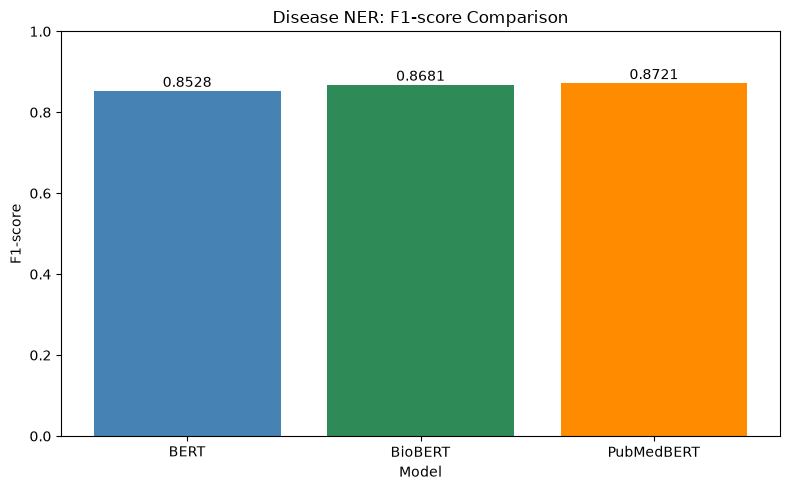

In [32]:
# Bar chart comparing the test F1-score of the three models
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Model"],
    results_df["F1"],
    color=["steelblue", "seagreen", "darkorange"]
)

plt.title("Disease NER: F1-score Comparison")
plt.xlabel("Model")
plt.ylabel("F1-score")
plt.ylim(0, 1)

# Print the exact score above each bar
for i, score in enumerate(results_df["F1"]):
    plt.text(
        i,
        score + 0.01,
        f"{score:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

### 10.2 Performance Analysis

The experimental results show that both biomedical-domain models outperform the general-domain BERT baseline in terms of F1-score.

- BERT achieves an F1-score of 0.8528.
- BioBERT achieves an F1-score of 0.8681, an improvement of 1.53 percentage points over BERT.
- PubMedBERT achieves the highest F1-score of 0.8721, an improvement of 1.93 percentage points over BERT and 0.40 percentage points over BioBERT.

These results suggest that biomedical-domain pre-training is beneficial for disease named entity recognition.

PubMedBERT's domain-specific vocabulary and biomedical pre-training may contribute to its improved performance. However, the improvement over BioBERT is relatively small.

It should also be noted that BERT and BioBERT results are obtained from the original group experiments, while PubMedBERT is trained on the cleaned dataset in this notebook. Although the data audit confirms that the non-empty samples match, differences in experimental settings may affect the comparison.

Although PubMedBERT achieves the highest F1-score and precision, BioBERT achieves the highest recall and token-level accuracy.

This suggests that BioBERT identifies a larger proportion of annotated disease entities, while PubMedBERT produces more precise disease entity predictions.

PubMedBERT provides the best overall balance between precision and recall, as reflected by its highest F1-score. However, no single model achieves the best performance across all four evaluation metrics.

## 11. Error Analysis

To better understand the strengths and limitations of the best-performing model, we conduct an error analysis of PubMedBERT on the NCBI Disease test set.

We compare the predicted BIO labels with the ground-truth annotations and examine incorrectly classified tokens and disease mentions.

The analysis focuses on:

- Missed disease mentions.
- Incorrectly predicted disease mentions.
- Incorrect disease entity boundaries.

In [33]:
# Get PubMedBERT predictions on the test set for error analysis
pubmedbert_predictions = pubmedbert_trainer.predict(
    pubmedbert_dataset["test"]
)

# Convert logits to predicted label ids
predicted_ids = np.argmax(
    pubmedbert_predictions.predictions,
    axis=-1
)

# Gold label ids, with -100 at the ignored positions
true_ids = pubmedbert_predictions.label_ids

print("Prediction shape:", predicted_ids.shape)
print("Ground truth shape:", true_ids.shape)

/opt/anaconda3/envs/neuralnet/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Prediction shape: (940, 130)
Ground truth shape: (940, 130)


In [34]:
# List every word where PubMedBERT's label differs from the gold label
error_rows = []

for i in range(len(clean_dataset["test"])):

    words = clean_dataset["test"][i]["tokens"]

    predictions = []
    true_labels = []

    # Keep only the first-subword positions so there is one label per word
    for p, l in zip(predicted_ids[i], true_ids[i]):
        if l != -100:
            predictions.append(id2label[p])
            true_labels.append(id2label[l])

    # Record each mismatched word together with its sentence for later inspection
    for j in range(len(true_labels)):
        if predictions[j] != true_labels[j]:

            error_rows.append({
                "Sentence ID": i,
                "Token": words[j],
                "True Label": true_labels[j],
                "Predicted Label": predictions[j],
                "Sentence": " ".join(words)
            })

# Total number of errors and the first few examples
error_df = pd.DataFrame(error_rows)

print("Total incorrectly classified tokens:", len(error_df))

display(error_df.head(15))

Total incorrectly classified tokens: 353


,Sentence ID,Token,True Label,Predicted Label,Sentence
0,3,T,I-Disease,B-Disease,By analysing tumour DNA from patients with spo...
1,3,T,I-Disease,B-Disease,By analysing tumour DNA from patients with spo...
2,7,A,B-Disease,O,Two of seventeen mutated T - PLL samples had a...
3,7,-,I-Disease,O,Two of seventeen mutated T - PLL samples had a...
4,7,T,I-Disease,O,Two of seventeen mutated T - PLL samples had a...
5,10,mutated,O,B-Disease,The evidence of a significant proportion of lo...
6,10,sporadic,B-Disease,O,The evidence of a significant proportion of lo...
7,10,T,I-Disease,B-Disease,The evidence of a significant proportion of lo...
8,20,isolated,O,B-Disease,Constitutional RB1 - gene mutations in patient...
9,20,unilateral,B-Disease,I-Disease,Constitutional RB1 - gene mutations in patient...


In [35]:
# Group the word-level errors into three types
def classify_error(true_label, predicted_label):

    # Missed = gold disease tag predicted as O, false positive = O predicted as disease, anything else is a B/I mix-up
    if true_label != "O" and predicted_label == "O":
        return "Missed disease token"

    elif true_label == "O" and predicted_label != "O":
        return "False positive disease token"

    else:
        return "BIO boundary error"


# Label each error and count how often each type occurs
error_df["Error Type"] = error_df.apply(
    lambda row: classify_error(
        row["True Label"],
        row["Predicted Label"]
    ),
    axis=1
)

error_summary = error_df["Error Type"].value_counts()

display(error_summary.to_frame("Count"))

,Count
Error Type,
False positive disease token,172
Missed disease token,118
BIO boundary error,63


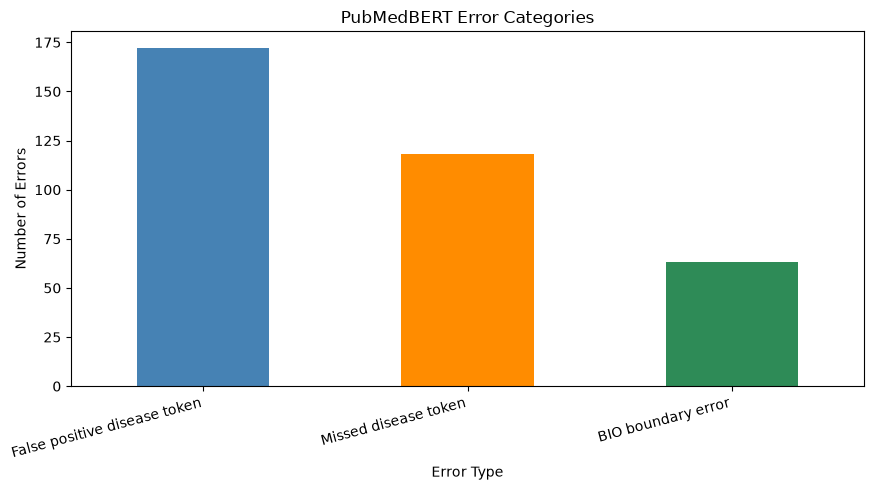

In [36]:
# Bar chart of the error type counts
plt.figure(figsize=(9, 5))

error_summary.plot(
    kind="bar",
    color=["steelblue", "darkorange", "seagreen"]
)

plt.title("PubMedBERT Error Categories")
plt.xlabel("Error Type")
plt.ylabel("Number of Errors")
plt.xticks(rotation=15, ha="right")

plt.tight_layout()
plt.show()

### 11.1 Case Study

We examine several representative prediction errors made by PubMedBERT on the test set.

Case 1 (missed disease tokens). In sentence 10, the token "sporadic" is annotated as B-Disease but predicted as O.

This shows that the model fails to identify the beginning of a disease mention. Such errors may result in incomplete disease entity recognition and reduce recall.

Case 2 (false positive disease tokens). In sentence 10, the token "mutated" is annotated as O but predicted as B-Disease.

The model incorrectly identifies a biomedical term as part of a disease entity. This suggests that the model may confuse disease-related terminology with actual disease mentions.

Case 3 (incorrect entity boundaries). In sentences 20, 21, and 23, the model repeatedly predicts "isolated" as B-Disease, although its ground-truth label is O.

At the same time, "unilateral" is annotated as B-Disease but predicted as I-Disease.

These predictions indicate that the model starts the disease entity one token earlier than the ground-truth annotation.

This example demonstrates that the model can identify disease-related expressions but may struggle to determine their exact boundaries.

### 11.2 Error Analysis Summary

PubMedBERT produces 353 token-level prediction errors on the test set.

False positive disease tokens are the most common error type, accounting for 172 errors (48.7%). This indicates that the model sometimes incorrectly classifies non-disease tokens as disease-related tokens.

Missed disease tokens account for 118 errors (33.4%), showing that the model still fails to identify some disease-related words.

BIO boundary errors account for 63 errors (17.8%). These errors indicate difficulties in identifying the exact beginning and continuation of disease entities.

The case studies also reveal that PubMedBERT sometimes includes additional descriptive words in disease mentions, resulting in incorrect entity boundaries.

Overall, although PubMedBERT achieves the highest F1-score among the three baseline models, improving its ability to distinguish disease mentions from surrounding biomedical terminology remains an important challenge.

## 12. Domain-Adaptive Pre-training (DAPT)

The project brief asks whether domain adaptation can improve generalisation. BioBERT and PubMedBERT beat plain BERT on NCBI Disease, but each was pre-trained on billions of words of biomedical text. This section tests a much cheaper form of domain adaptation, domain-adaptive pre-training (DAPT; Gururangan et al., 2020). We continue the masked-language-model (MLM) training of `bert-base-cased` on unlabelled PubMed abstracts and then fine-tune it for disease NER with exactly the same protocol, data and seeds as the BERT baseline. Only the starting weights change, so any difference in NER scores can be attributed to the extra pre-training.

It has four subsections: setup, the DAPT method and corpus, the results (pre-training and NER), and a discussion of why DAPT did not help.

This section was run in a separate notebook with the repository code (`ner/` and `dapt/`, see `parts/6_dapt.ipynb`), and its outputs are copied here unchanged. Its BERT baseline is a three-seed re-run with the repository training script, which selects the epoch by validation strict F1, so its scores differ slightly from the single BERT run in Section 7.

### 12.1 Setup

This subsection finds the repository root (or clones it on Colab), loads the plotting and table libraries, and defines a small helper that prints selected functions from the repository's code, so the key DAPT code can be shown without re-running training. All results below are read from files saved by the training runs in `dapt/results/`.

In [1]:
import os, sys, json, glob
from pathlib import Path
from collections import Counter

# Work from the repository root whether the notebook is opened from parts/ or from the root.
IN_COLAB = "google.colab" in sys.modules
if not Path("ner").exists() and Path("../ner").exists():
    os.chdir("..")
# On Colab, fetch the repository and the pinned library versions used for the runs.
if IN_COLAB and not Path("ner").exists():
    !git clone -b final-submission https://github.com/lofty14/bert-ner-baseline.git
    %cd bert-ner-baseline
    !pip -q install transformers==5.22.0 accelerate==1.15.0 seqeval==1.2.2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(".").resolve()
sys.path.insert(0, str(ROOT))          # make the shared ner/ package importable
pd.set_option("display.precision", 2)
print("repo root:", ROOT)

repo root: .../group_project


In [2]:
import ast

def show_source(path, names):
    """Print the source of selected top-level functions/classes without importing the module."""
    text = Path(path).read_text()
    tree = ast.parse(text)                 # parse only; nothing in the module is executed
    lines = text.splitlines()
    for node in tree.body:
        if getattr(node, "name", None) in names:
            # lineno / end_lineno give the exact line range of the definition
            print("\n".join(lines[node.lineno - 1:node.end_lineno]))
            print()

### 12.2 Method and Corpus

DAPT has two stages: continued MLM pre-training of `bert-base-cased` on a disease-focused PubMed corpus, then ordinary NER fine-tuning. The corpus, the leakage check, the training settings and the evaluation are described below.

The corpus is 30,000 English PubMed abstracts from the MeSH *Diseases* category, sampled evenly across publication years (query and PMID list in `dapt/results/corpus_audit.json`); 115 records had no abstract.

NCBI Disease is itself built from PubMed abstracts, so the corpus was checked for leakage in two passes before training: by PMID (2 documents removed, both from the NCBI training split) and by sentence text against the NCBI dev and test sentences (none removed). No dev or test text was seen during pre-training.

Of the remaining abstracts, 29,257 (about 5.9 M words, 9.8 M word pieces) were used for training and 626 were held out to measure MLM perplexity. The split is a fixed hash of the PMID, so it is reproducible.

MLM training used non-overlapping 256-token windows, dynamic masking of 15% of tokens, batch size 32 and learning rate 5e-5 with 6% linear warm-up. We kept two checkpoints: 1 epoch (1,632 steps, 0.8 h) and 3 epochs (4,896 steps, 2.2 h) on an Apple M-series GPU.

Each checkpoint was then fine-tuned with the unified protocol (learning rate 2e-5, batch size 8, 3 epochs, epoch selected on dev strict F1) for seeds 1, 2 and 3, and scored with seqeval strict entity-level precision, recall and F1 (IOB2) on the test set. The BERT baseline in the tables below was re-run under the same protocol and seeds, so the comparison is paired by seed.

The cell below prints the windowing and masking code and the recorded training statistics.

In [3]:
# Show the two pieces of code that define DAPT's input: windowing and masking.
show_source("ner/dapt.py", ["make_windows", "MLMCollator"])

# Statistics recorded by the 3-epoch DAPT run.
d = json.load(open("dapt/results/bert_dapt_3ep.dapt.json"))
print("corpus:", d["corpus"]["documents"], "documents,", f'{d["corpus"]["train_tokens"]:,}', "training tokens")
print("MLM config:", {k: d["config"][k] for k in ["epochs", "batch_size", "lr", "max_length", "mlm_probability"]})
# Perplexity on the 626 held-out abstracts, before and after continued pre-training
print("validation perplexity: %.2f -> %.2f" % (d["valid_perplexity"]["initial"], d["valid_perplexity"]["final"]))
print("training time: %.1f h" % (d["seconds"]["total"] / 3600))

def make_windows(texts, tokenizer, max_length):
    """Non-overlapping [CLS] + pieces + [SEP] windows of at most max_length tokens."""
    size = max_length - 2
    features = []
    for start in range(0, len(texts), 1000):
        ids = tokenizer(texts[start:start + 1000], add_special_tokens=False, truncation=False,
                        verbose=False)["input_ids"]
        for doc in ids:
            for i in range(0, len(doc), size):
                piece = [tokenizer.cls_token_id] + doc[i:i + size] + [tokenizer.sep_token_id]
                features.append({"input_ids": piece,
                                 "special_tokens_mask": [1] + [0] * (len(piece) - 2) + [1]})
    return features

class MLMCollator:
    """Dynamic masking for training windows; windows that already carry labels are only padded."""

    def __init__(self, tokenizer, mlm_probability):
        self.mlm = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm_probability=mlm_probability)
        self.pad_id =

### 12.3 Results

We first check that the continued pre-training worked, using the MLM loss on the held-out abstracts, and then compare NER scores with and without DAPT over the same three seeds.

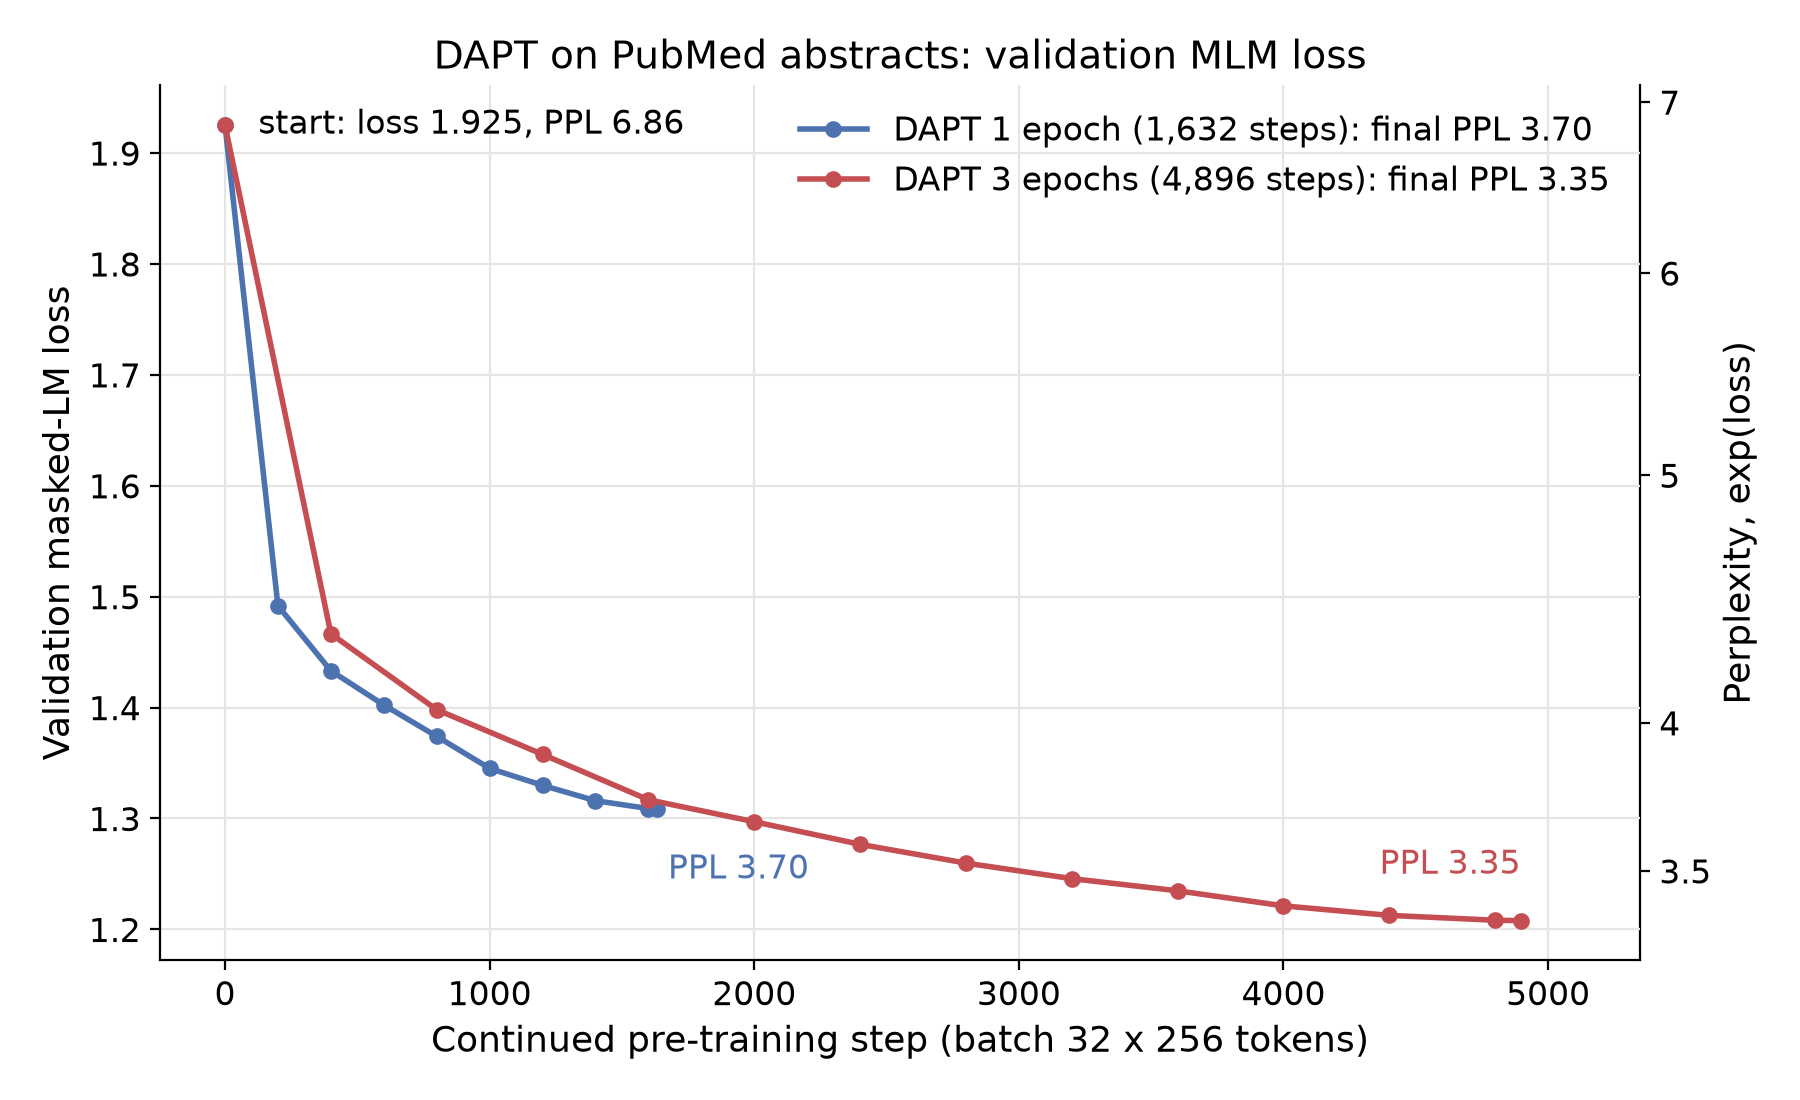

In [4]:
from IPython.display import Image, display

# Validation MLM loss during continued pre-training (saved by dapt/plot_dapt.py).
display(Image("dapt/figs/mlm_valid_loss.png", width=600))

The pre-training worked as intended. Perplexity on the 626 held-out abstracts fell from 6.86 for the original BERT to 3.70 after 1 epoch and 3.35 after 3 epochs, and the validation loss was still decreasing slowly at the end (plot above). The model clearly learned to predict biomedical text better; the question is whether that helps NER.

The next three cells give the NER scores: the summary table over seeds, the per-seed test F1, and the paired comparison of the 3-epoch model against BERT.

In [5]:
# Summary table: mean ± std over seeds 1-3 for BERT and both DAPT checkpoints
# (the model-selection details after this heading are omitted).
print(Path("dapt/results/results.md").read_text().split("#### model selection")[0])

Scores are percentages, mean ± sample std over seeds. `default` = seqeval default mode, `strict` = mode='strict', scheme=IOB2.

### precision: fp32; dev selection metric: strict_f1

#### dev (selected epoch)

| model | n seeds | P (default) | R (default) | F1 (default) | P (strict) | R (strict) | F1 (strict) | token acc |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| bert | 3 (1,2,3) | 81.17 ± 0.37 | 87.25 ± 0.48 | 84.10 ± 0.40 | 83.60 ± 0.90 | 87.00 ± 0.48 | 85.26 ± 0.56 | 98.63 ± 0.05 |
| bert+dapt1ep | 3 (1,2,3) | 80.17 ± 0.47 | 86.79 ± 0.13 | 83.34 ± 0.21 | 82.06 ± 0.76 | 86.57 ± 0.07 | 84.26 ± 0.36 | 98.59 ± 0.04 |
| bert+dapt3ep | 3 (1,2,3) | 80.19 ± 0.62 | 86.91 ± 0.22 | 83.42 ± 0.26 | 82.13 ± 0.84 | 86.79 ± 0.22 | 84.39 ± 0.38 | 98.60 ± 0.04 |

#### test, dev-selected epoch

| model | n seeds | P (default) | R (default) | F1 (default) | P (strict) | R (strict) | F1 (strict) | token acc |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| bert | 3 (1,2,3) | 81.57 ± 0.11 | 87.29 ±

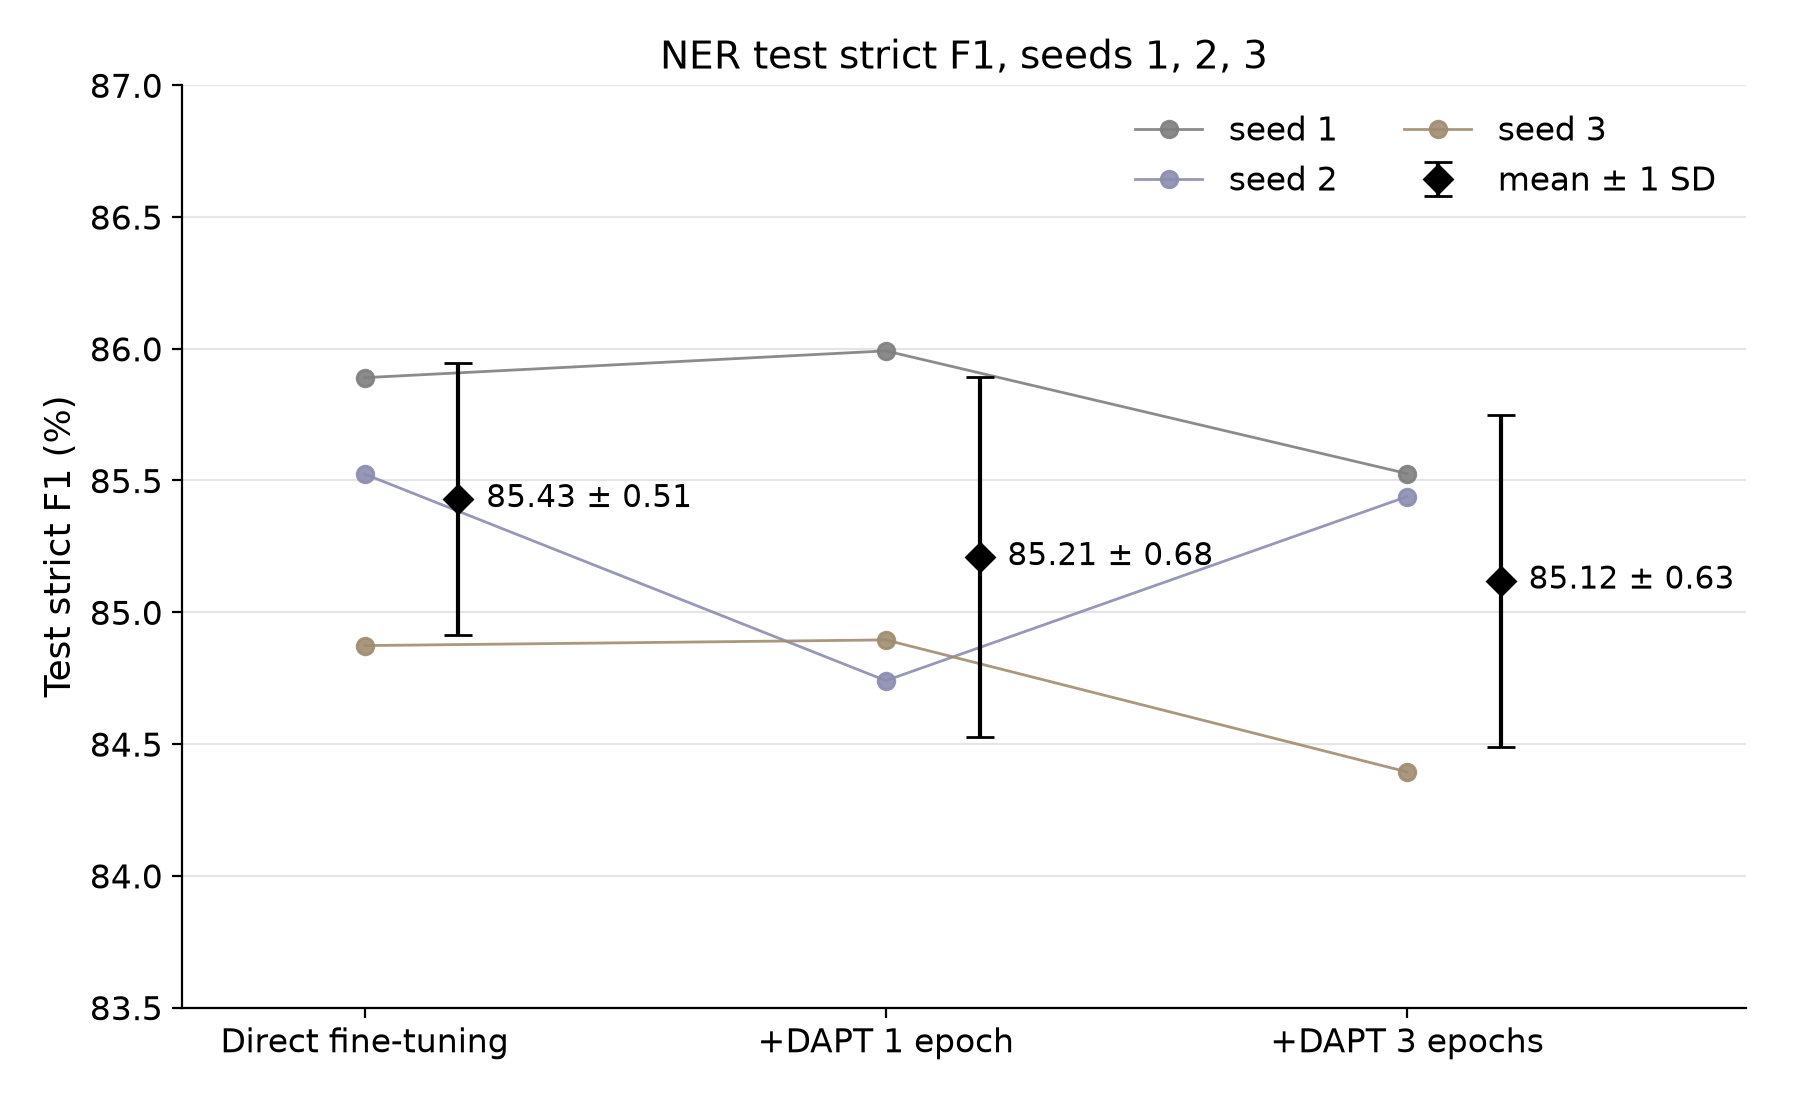

In [6]:
# Test strict F1 per seed; lines join the same seed across models.
display(Image("dapt/figs/ner_f1_paired.png", width=650))

In [7]:
# Paired differences (DAPT 3 epochs minus BERT) for each seed, on dev and test.
print(Path("dapt/results/compare_dapt3ep.md").read_text()[:4000])

Paired comparison `bert+dapt3ep` − `bert` over seeds 1, 2, 3 (precision fp32, dev selection strict_f1). Scores are percentages, seqeval strict IOB2 entity level; Δ = b − a.

#### dev (selected epoch)

| seed | bert P | bert R | bert F1 | bert+dapt3ep P | bert+dapt3ep R | bert+dapt3ep F1 | ΔP | ΔR | ΔF1 |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 1 | 82.59 | 86.79 | 84.63 | 81.45 | 87.04 | 84.15 | -1.14 | +0.25 | -0.48 |
| 2 | 83.92 | 87.55 | 85.70 | 81.87 | 86.66 | 84.20 | -2.05 | -0.89 | -1.50 |
| 3 | 84.30 | 86.66 | 85.46 | 83.07 | 86.66 | 84.83 | -1.23 | +0.00 | -0.64 |
| mean ± std |  |  |  |  |  |  | -1.47 ± 0.50 | -0.21 ± 0.60 | -0.87 ± 0.55 |
| seeds Δ > 0 |  |  |  |  |  |  | 0/3 | 1/3 | 0/3 |

#### test, dev-selected epoch

| seed | bert P | bert R | bert F1 | bert+dapt3ep P | bert+dapt3ep R | bert+dapt3ep F1 | ΔP | ΔR | ΔF1 |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 1 | 84.63 | 87.19 | 85.89 | 83.17 | 88.02 | 85.53 | -1.46 | +0.83 | -0.36 |
| 2 | 84.02

### 12.4 Discussion

In short, DAPT lowered perplexity but did not improve NER. This subsection looks at the size of the effect, where the errors changed, why the gain did not appear, and what we take from it.

On the test set, strict F1 was 85.43 ± 0.51 for BERT, 85.21 ± 0.68 after 1 epoch of DAPT and 85.12 ± 0.63 after 3 epochs. Paired by seed, the 3-epoch model changed F1 by −0.31 ± 0.20 points and was slightly lower in all three seeds; on the dev set the drop was −0.87 ± 0.55. Each drop is smaller than the spread between seeds of the same model, so the result is best read as no gain, possibly a small loss, and certainly not the 1.5–2 point gain that BioBERT and PubMedBERT show over BERT.

DAPT raised test recall (+0.49 ± 0.43 for 3 epochs) but lowered precision (−1.04 ± 0.37, all three seeds). The entity-level error analysis (`dapt/results/error_analysis_dapt3ep.md`, pooled over seeds) shows where this comes from: the DAPT model found 14 more gold entities but produced 40 more false positives, 25 of them spurious (no overlap with any gold mention) and 15 with wrong boundaries. Typical new errors are biomedical words that are not disease mentions in this annotation scheme: the twin-study abbreviations *DZ* and *MZ* (dizygotic / monozygotic), the gene name *APC* next to the disease *FAP*, and generic words such as *deficiency* or *congenital* on their own. Our reading is that the MLM stage made the model more sensitive to biomedical vocabulary in general, which helps it notice more mentions but also makes it tag terms that look disease-like.

The main reason for the missing gain is scale. Our corpus is about 10 M word pieces and 3 epochs, while BioBERT was trained on about 18 B words of PubMed and PMC and PubMedBERT on about 3 B words from scratch with an in-domain vocabulary. DAPT also keeps BERT's general WordPiece vocabulary, so disease names are still split into many pieces. With labelled data this small (about 5,000 training sentences), fine-tuning already adapts BERT to the task, and the extra pre-training at this scale is not enough to change what the classifier learns.

We draw three conclusions. First, a cheap DAPT run is not a substitute for a biomedical pre-trained model: for this task, starting from BioBERT or PubMedBERT is more effective than adapting BERT ourselves. Second, lower perplexity did not translate into better NER, so MLM loss alone is not a good proxy for downstream gains. Third, the next steps would be a much larger corpus with longer training, task-adaptive pre-training on unlabelled text close to the NCBI abstracts, or applying DAPT on top of BioBERT rather than plain BERT; more seeds would also be needed to detect differences below half a point.

## 13. Conclusion

### 13.1 Summary of Findings

In this project, we investigate disease named entity recognition using three pre-trained language models: BERT, BioBERT, and PubMedBERT.

We first conduct a data audit to compare the Hugging Face NCBI Disease dataset with the CoNLL version. The audit identifies one empty sample in each dataset split. After removing these samples, all three splits exactly match the CoNLL dataset.

We then preprocess the dataset using subword tokenization and BIO label alignment, and evaluate the three models using precision, recall, F1-score, and accuracy.

The experimental results show that:

- BERT achieves a test F1-score of 0.8528.
- BioBERT achieves a test F1-score of 0.8681.
- PubMedBERT achieves the highest test F1-score of 0.8721.

Both biomedical-domain models outperform the general-domain BERT baseline. These results suggest that biomedical-domain pre-training can improve disease named entity recognition.

PubMedBERT achieves an improvement of 1.93 percentage points in F1-score over BERT and 0.40 percentage points over BioBERT.

In a separate experiment (Section 12), domain-adaptive pre-training of BERT on about 10 M word pieces of PubMed abstracts lowered the masked-language-model perplexity from 6.86 to 3.35 but did not improve test F1 across three fine-tuning seeds.

The error analysis shows that false positive disease tokens are the most common prediction errors, followed by missed disease tokens and BIO boundary errors.

Overall, PubMedBERT achieves the best performance in our experiments, although accurate disease entity boundaries and the distinction between disease mentions and other biomedical terminology remain challenging.

### 13.2 Limitations and Future Work

There are several limitations in this project.

First, the BERT and BioBERT results are obtained from the original group experiments, while PubMedBERT is trained on the cleaned dataset in this notebook. Although the data audit confirms that the non-empty samples are identical, differences in experimental settings may affect the comparison.

Second, apart from the DAPT experiment in Section 12, the experiments do not evaluate performance across multiple random seeds. Therefore, the stability of the reported improvements has not been established.

Third, the error analysis focuses on PubMedBERT. A comparative error analysis across all three models could provide further insights into their strengths and weaknesses.

Future work could include:

- Training all models under identical experimental settings.
- Repeating experiments with multiple random seeds.
- Investigating alternative hyperparameters and training strategies.
- Exploring methods to improve disease entity boundary recognition.
- Evaluating parameter-efficient fine-tuning methods such as LoRA.